# Car Price Prediction — Intermediate Assessment

**Business question:** Which vehicle characteristics predict car price, and how accurately can they do so? This notebook uses the provided 205-car dataset. Run all cells from top to bottom from the repository root. The test set is reserved for final comparisons; model tuning uses training data only.


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
DATA_PATH = Path('data/CarPrice_Assignment.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('car-price-assignment/data/CarPrice_Assignment.csv')
df = pd.read_csv(DATA_PATH)
print('Rows and columns:', df.shape)
display(df.head())



Rows and columns: (205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


## 1. Inspect and prepare the data

`car_ID` is a row identifier, so it must not be used to predict price. `CarName` contains model names; we extract its first word as a brand and normalize known spelling variants. We do not use the full model name because it is almost unique and may encourage memorization. Numeric values are standardized for SVR; categorical values are one-hot encoded. All preprocessing is fitted on training folds only.


In [4]:
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
display(df['price'].describe().to_frame('price'))
display(df.isna().sum().loc[lambda s: s > 0].to_frame('missing'))

cars = df.drop(columns='car_ID').copy()
cars['brand'] = cars['CarName'].str.split().str[0].str.lower().replace({
    'maxda': 'mazda', 'porcshce': 'porsche', 'toyouta': 'toyota',
    'vokswagen': 'volkswagen', 'vw': 'volkswagen'
})
cars = cars.drop(columns='CarName')
X = cars.drop(columns='price')
y = cars['price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print('Training / test rows:', len(X_train), len(X_test))
print('Numeric:', num_cols)
print('Categorical:', cat_cols)


Missing values: 0
Duplicate rows: 0


,price
count,205.000000
mean,13276.710571
std,7988.852332
min,5118.000000
25%,7788.000000
50%,10295.000000
75%,16503.000000
max,45400.000000


,missing


Training / test rows: 164 41
Numeric: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']
Categorical: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']


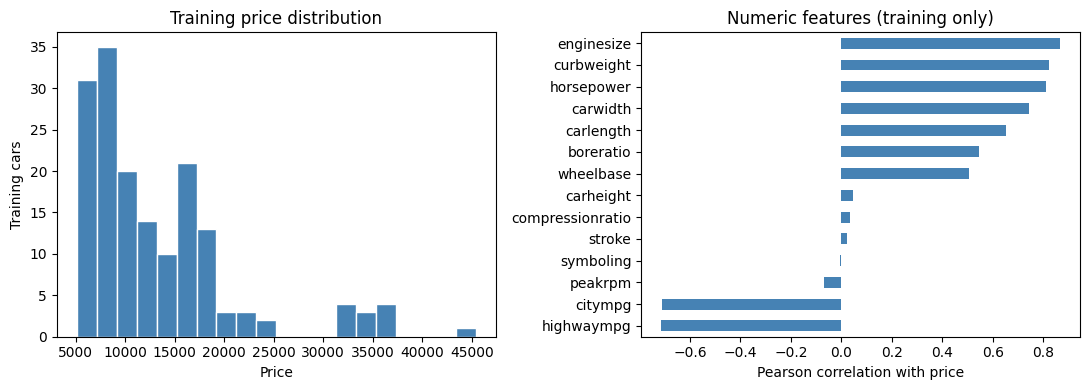

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(y_train, bins=20, color='steelblue', edgecolor='white')
axes[0].set(xlabel='Price', ylabel='Training cars', title='Training price distribution')
train_correlations = pd.concat([X_train[num_cols], y_train], axis=1).corr()['price'].drop('price')
train_correlations.sort_values().plot.barh(ax=axes[1], color='steelblue')
axes[1].set(xlabel='Pearson correlation with price', title='Numeric features (training only)')
plt.tight_layout()
plt.show()


## 2. Train the five requested regressors

Each estimator gets its own preprocessing pipeline. The same held-out cars are used for all five comparisons. Higher R² and lower MSE/MAE are better; MAE is in the original price units. A small test sample makes estimates uncertain, so results should be validated with additional market data before business use.


In [6]:
def make_pipeline(estimator):
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')),
                        ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                            ('encode', OneHotEncoder(handle_unknown='ignore'))])
    prep = ColumnTransformer([('numeric', numeric, num_cols),
                              ('categorical', categorical, cat_cols)])
    return Pipeline([('preprocess', prep), ('model', estimator)])

def scores(name, fitted_model):
    prediction = fitted_model.predict(X_test)
    return {'Model': name, 'R2': r2_score(y_test, prediction),
            'MSE': mean_squared_error(y_test, prediction),
            'MAE': mean_absolute_error(y_test, prediction)}

algorithms = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'Support Vector Regressor': SVR(C=1000, epsilon=100),
}
fitted = {name: make_pipeline(model).fit(X_train, y_train)
          for name, model in algorithms.items()}
results = pd.DataFrame([scores(name, model) for name, model in fitted.items()])
results = results.sort_values(['R2', 'MAE'], ascending=[False, True]).reset_index(drop=True)
display(results.round(3))
base_winner = results.iloc[0]['Model']
print(f'Best baseline on held-out R²: {base_winner}. Test R²={results.iloc[0].R2:.3f}, '
      f'MAE={results.iloc[0].MAE:,.2f}.')


,Model,R2,MSE,MAE
0,Random Forest,0.958,3.283770e+06,1270.782
1,Gradient Boosting,0.928,5.684860e+06,1666.640
2,Decision Tree,0.906,7.396941e+06,1785.776
3,Linear Regression,0.901,7.808716e+06,1807.704
4,Support Vector Regressor,0.505,3.905477e+07,3489.495


Best baseline on held-out R²: Random Forest. Test R²=0.958, MAE=1,270.78.


## 3. Important price predictors

Permutation importance measures how much test R² falls when one **original input column** is shuffled. One-hot brand categories remain grouped as one variable. Scores are predictive associations, not causal effects; correlated vehicle specifications can share importance. The ranking is descriptive and is not used to choose or tune models on the test set.


,Variable,Mean R2 decrease,Std. deviation
14,enginesize,0.817,0.127
11,curbweight,0.131,0.024
22,highwaympg,0.009,0.003
19,horsepower,0.006,0.003
9,carwidth,0.004,0.002
21,citympg,0.002,0.002
18,compressionratio,0.002,0.001
23,brand,0.002,0.002
16,boreratio,0.002,0.002
17,stroke,0.002,0.001


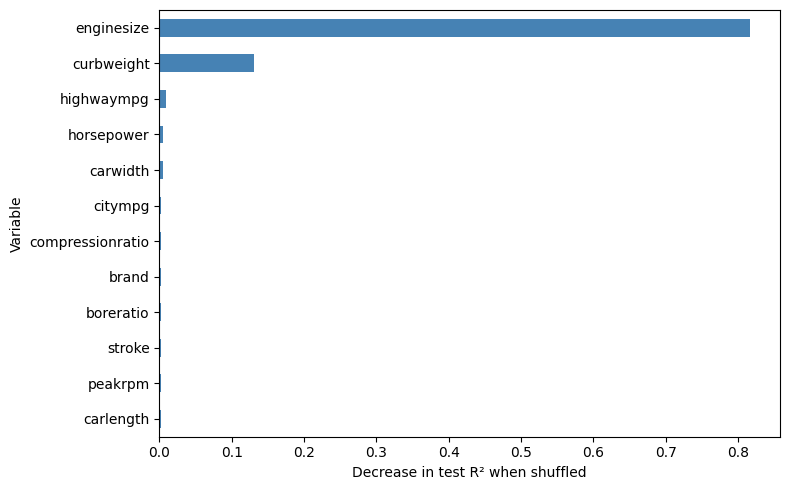

Most influential measured variables: enginesize, curbweight, highwaympg, horsepower, carwidth


In [7]:
importance = permutation_importance(
    fitted[base_winner], X_test, y_test, scoring='r2',
    n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1
)
important = pd.DataFrame({
    'Variable': X_test.columns,
    'Mean R2 decrease': importance.importances_mean,
    'Std. deviation': importance.importances_std
}).sort_values('Mean R2 decrease', ascending=False)
display(important.head(12).round(3))
important.head(12).iloc[::-1].plot.barh(x='Variable', y='Mean R2 decrease', legend=False,
                                         figsize=(8, 5), color='steelblue')
plt.xlabel('Decrease in test R² when shuffled')
plt.tight_layout()
plt.show()
print('Most influential measured variables:', ', '.join(important.head(5)['Variable']))


## 4. Hyperparameter tuning

Tune **Random Forest and Gradient Boosting** with 5-fold cross-validation on the training split, optimizing R². We choose the tuned candidate using cross-validation scores, then compare its held-out result with its untuned version. The held-out set is never used to select hyperparameters.


In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search_spaces = {
    'Random Forest': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [None, 8],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': [0.7, 1.0],
    },
    'Gradient Boosting': {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.05, 0.1],
        'model__max_depth': [2, 3],
        'model__min_samples_leaf': [1, 3],
    },
}
searches = {}
for name, parameters in search_spaces.items():
    search = GridSearchCV(make_pipeline(algorithms[name]), parameters,
                          scoring='r2', cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    print(name, 'CV R²:', round(search.best_score_, 3), 'parameters:', search.best_params_)

tuned_name = max(searches, key=lambda name: searches[name].best_score_)
tuned = searches[tuned_name].best_estimator_
comparison = pd.DataFrame([
    scores(tuned_name + ' (untuned)', fitted[tuned_name]),
    scores(tuned_name + ' (tuned)', tuned)
])
display(comparison.round(3))
print('CV-selected candidate:', tuned_name)
print('Held-out R² change:', round(comparison.iloc[1].R2 - comparison.iloc[0].R2, 3))
print('Held-out MAE change:', round(comparison.iloc[1].MAE - comparison.iloc[0].MAE, 2))


Random Forest CV R²: 0.899 parameters: {'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Gradient Boosting CV R²: 0.907 parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_leaf': 3, 'model__n_estimators': 100}


,Model,R2,MSE,MAE
0,Gradient Boosting (untuned),0.928,5684860.239,1666.640
1,Gradient Boosting (tuned),0.923,6080604.834,1843.067


CV-selected candidate: Gradient Boosting
Held-out R² change: -0.005
Held-out MAE change: 176.43


## 5. Business interpretation and limitations

The results table identifies the strongest *baseline* by held-out R², while the tuning comparison shows whether tuning improved that specific candidate. The importance table answers which measured variables most affect predictions; it does not establish that changing a feature will cause the same change in price. This dataset contains only 205 records and does not identify collection date, geographic coverage, or inflation adjustments. Treat these predictions as an assessment exercise, not current US market prices. Brand may capture positioning and other unobserved factors. A larger, recent external sample is needed before decisions about manufacturing or pricing.
